<a href="https://colab.research.google.com/github/Juliusp36/GinyuForce2/blob/main/notebooks/03%20low%20rank.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import subprocess
import sys

USER = "Juliusp36"
REPO = "GinyuForce2"

if os.path.exists(REPO):
  subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
  subprocess.run(
    ["git", "clone", f"https://github.com/{USER}/{REPO}.git", REPO],
    check=True)

sys.path.insert(0, f"{REPO}/src")
from evaluate import split_ratings, to_matrix, rmse
from models import bias_baseline

This cell imports the contents located in the files in src/evaluate.py and src/models.py.

In [ ]:
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if not os.path.exists("ml-100k"):
  urllib.request.urlretrieve(
  "https://files.grouplens.org/datasets/movielens/ml-100k.zip", "ml-100k.zip")
  zipfile.ZipFile("ml-100k.zip").extractall()

ratings = pd.read_csv("ml-100k/u.data", sep="\\t", names=["user", "item", "rating", "time"])


train, test = split_ratings(ratings, seed=0)
fit, val = split_ratings(train, seed=1)
print("fit:", len(fit), "validation:", len(val), "test:", len(test))

/tmp/ipykernel_1867/1665530400.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  ratings = pd.read_csv("ml-100k/u.data", sep="\\t", names=["user", "item", "rating", "time"])


fit: 81200 validation: 8832 test: 9968


This cell downloads the MovieLens 100k dataset into Python and splits it into multiple subsets using the split ratings function from the last milestone.

In [ ]:
R_fit = to_matrix(fit)
known_fit = ~np.isnan(R_fit)
val_truth = val["rating"].to_numpy()
val_u = val["user"].to_numpy() - 1
val_i = val["item"].to_numpy() - 1

def score_at(P, rows, cols, truth):
  "RMSE for selected entries of a prediction matrix."
  pred = np.clip(P[rows, cols], 1, 5)
  return rmse(pred, truth)

Using the fit partition, this cell constructs a user-by-movie rating matrix and identifies which ratings are known. It also prepares the validation data by extracting the actual ratings and their corresponding user and movie indices. This will be used to choose the configurations for the model as opposed to computign averages for SVD.

In [ ]:
def baseline_matrix(R):
  # Full matrix: overall mean plus user and movie effects.
  mu, b_user, b_item = bias_baseline(R)
  return mu + b_user[:, None] + b_item[None, :]

B_fit = baseline_matrix(R_fit)
baseline_val_rmse = score_at(B_fit, val_u, val_i, val_truth)
print("Baseline validation RMSE:", round(baseline_val_rmse, 4))

Baseline validation RMSE: 0.9731


This block of code cuilds the baseline prediction matrix from the previous 'R_fit' matrix we created in the previous code block. It  predicts ratings based on the overall average rating, individual user biases, and movie biases. This baseline model is then evaluated against the validation dataset using RMSE to measure prediction accuracy (This was the one named 'val' created from our splitting).

In [ ]:
def rank_k(U, s, Vt, k):
# Build a rank-k matrix from an already computed SVD.
  return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

This cell simply takes the input of an already computed SVD and returns an partition of it which is the desired rank (k).

In [ ]:
mu_fit = np.nanmean(R_fit)

n_item = known_fit.sum(axis=0)

item_mean = np.full(R_fit.shape[1], mu_fit)

has_rating = n_item > 0

item_mean[has_rating] = (
  np.nansum(R_fit, axis=0)[has_rating] / n_item[has_rating])

F = np.where(known_fit, R_fit, item_mean[None, :])

U1, s1, Vt1 = np.linalg.svd(F, full_matrices=False)

This block of code fills the gaps within the matrix with the previously computed movie averages. It does this by using 'np.where' to distinguish between the normal values and the gaps within the matrix. Finally, svd is ran on the full matrix.

In [ ]:
X_fit = np.where(known_fit, R_fit - B_fit, 0.0)
U2, s2, Vt2 = np.linalg.svd(X_fit, full_matrices=False)

This block of code performs the SVD on the differences between the actual ratings and the baseline predictions

In [ ]:
ks = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100]
val_err1, val_err2 = [], []

for k in ks:
  P1 = rank_k(U1, s1, Vt1, k)
  P2 = rank_k(U2, s2, Vt2, k) + B_fit
  val_err1.append(score_at(P1, val_u, val_i, val_truth))
  val_err2.append(score_at(P2, val_u, val_i, val_truth))

best_k1 = ks[int(np.argmin(val_err1))]
best_k2 = ks[int(np.argmin(val_err2))]
print("Best Model 1 k:, best_k1, validation RMSE:", min(val_err1))
print("Best Model 2 k:, best_k2, validation RMSE:", min(val_err2))

Best Model 1 k:, best_k1, validation RMSE: 0.9934477108911378
Best Model 2 k:, best_k2, validation RMSE: 0.9492241710885614


This block of code evaluates both SVD models using different rank values (k) on the validation dataset. A prediction matrix is constructed for each rank and then compared to the validation matrix using RSME. Finally, we get the best version for each model.

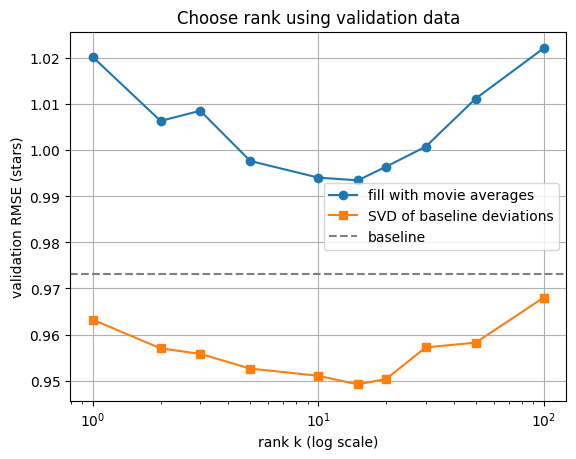

In [ ]:
plt.semilogx(ks, val_err1, "o-", label="fill with movie averages")
plt.semilogx(ks, val_err2, "s-", label="SVD of baseline deviations")
plt.axhline(baseline_val_rmse, color="gray", linestyle="--",

label="baseline")
plt.xlabel("rank k (log scale)")
plt.ylabel("validation RMSE (stars)")
plt.title("Choose rank using validation data")
plt.grid()
plt.legend()
plt.savefig("validation_rmse_vs_k.png", dpi=150)
plt.show()

This block of code creates a graph that compares the validation RMSE for both SVD models at different ranks of length k. Additionally, it includes a baseline for comparision. We see that "SVD of baseline deviations" model performed better.

In [ ]:
def iterative_svd_predict(R, k, n_iter=10):
  "Predict ratings by repeatedly imputing missing deviations."
  known = ~np.isnan(R)
  B = baseline_matrix(R)
  X = np.where(known, R - B, 0.0)

  for _ in range(n_iter):
    U, s, Vt = np.linalg.svd(X, full_matrices=False)
    L = rank_k(U, s, Vt, k)
    X = np.where(known, R - B, L)

  return L + B

In this code block, we define a new SVD model that repeatedly fills in the gaps within the matrix using the current rank k predictions. The model starts by calculating the differences between the actual ratings and the baseline predictions. It then runs SVD multiple times, updating the missing values with new predictions while keeping the known deviations the same. After the iterations are complete, the baseline is added back to produce the final predicted ratings.

In [27]:
ks_iter = [2, 5, 10, 20]
val_err3 = []
for k in ks_iter:
  P3 = iterative_svd_predict(R_fit, k, n_iter=10)
  val_err3.append(score_at(P3, val_u, val_i, val_truth))

best_k3 = ks_iter[int(np.argmin(val_err3))]
print("Best iterative rank:", best_k3)
print("Best validation RMSE:", min(val_err3))

Best iterative rank: 2
Best validation RMSE: 0.9431464026691649


In this block of code. We test the iterative SVD model using rank k values of 2, 5, 10, and 20. 10 iterations are ran within the error replacing framework as stated above. After each rank is tested, we calculate the RMSE using the validation dataset and store the results. Finally, the code identifies which rank produced the lowest RMSE and prints that rank along with its validation error.

In [30]:
R_train = to_matrix(train)
test_truth = test["rating"].to_numpy()
test_u = test["user"].to_numpy() - 1
test_i = test["item"].to_numpy() - 1

B_train = baseline_matrix(R_train)
test_baseline = score_at(B_train, test_u, test_i, test_truth)

if min(val_err3) < min(val_err2) and min(val_err3) < min(val_err1):
  test_prediction = iterative_svd_predict(R_train, best_k3, n_iter=10)
  chosen_model = "iterative SVD"

elif min(val_err2) < min(val_err1):
  known_train = ~np.isnan(R_train)
  X_train = np.where(known_train, R_train - B_train, 0.0)
  U, s, Vt = np.linalg.svd(X_train, full_matrices=False)
  test_prediction = rank_k(U, s, Vt, best_k2) + B_train
  chosen_model = "baseline plus low-rank deviations"

else:
  known_train = ~np.isnan(R_train)
  mu_train = np.nanmean(R_train)
  n_item_train = known_train.sum(axis=0)
  means_train = np.full(R_train.shape[1], mu_train)
  has_train = n_item_train > 0
  means_train[has_train] = (
  np.nansum(R_train, axis=0)[has_train] / n_item_train[has_train])
  F_train = np.where(known_train, R_train, means_train[None, :])
  U, s, Vt = np.linalg.svd(F_train, full_matrices=False)
  test_prediction = rank_k(U, s, Vt, best_k1)
  chosen_model = "SVD of movie-average-filled matrix"

test_rmse = score_at(test_prediction, test_u, test_i, test_truth)
print("Chosen model:", chosen_model)
print("Baseline test RMSE:", round(test_baseline, 4))
print("Chosen model test RMSE:", round(test_rmse, 4))

Chosen model: iterative SVD
Baseline test RMSE: 0.9545
Chosen model test RMSE: 0.9286


In this code block, we use the full training dataset to build our final model. First we calculate the baseline predictions. Then, using the RMSE validation results from the previous, we determine the best performing SVD. Depending on which model is selected, we rebuild it using the full training dataset and its best rank k. Finally, we test the selected model against the test dataset and compare its RMSE to the baseline to see if it performs better.

# Exercises

In [31]:
# Does filling matter
F_overall = np.where(known_fit, R_fit, mu_fit)
F_three = np.where(known_fit, R_fit, 3.0)

U_overall, s_overall, Vt_overall = np.linalg.svd(F_overall, full_matrices=False)
U_three, s_three, Vt_three = np.linalg.svd(F_three, full_matrices=False)

ks_fill = [2, 5, 10, 20]
fill_movie, fill_overall, fill_three = [], [], []

for k in ks_fill:
    P_movie = rank_k(U1, s1, Vt1, k)
    P_overall = rank_k(U_overall, s_overall, Vt_overall, k)
    P_three = rank_k(U_three, s_three, Vt_three, k)

    fill_movie.append(score_at(P_movie, val_u, val_i, val_truth))
    fill_overall.append(score_at(P_overall, val_u, val_i, val_truth))
    fill_three.append(score_at(P_three, val_u, val_i, val_truth))

for i, k in enumerate(ks_fill):
    print("Rank:", k)
    print("Movie average:", round(fill_movie[i], 4))
    print("Overall average:", round(fill_overall[i], 4))
    print("3 stars:", round(fill_three[i], 4))
    print()

Rank: 2
Movie average: 1.0063
Overall average: 1.0728
3 stars: 1.1192

Rank: 5
Movie average: 0.9976
Overall average: 1.0568
3 stars: 1.0856

Rank: 10
Movie average: 0.994
Overall average: 1.0511
3 stars: 1.0749

Rank: 20
Movie average: 0.9964
Overall average: 1.0545
3 stars: 1.0788



As we can see, filling with the movie average produces the best output, thus we can conclude that filling does matter.

### 2. Understand the full-rank check.

Model 2 uses the differences between the actual ratings and baseline predictions, while filling the missing values with zero. Because the missing values were originally filled with zero, adding the baseline back gives us the baseline predictions for those missing ratings.

This does not mean the model learned useful preferences because it only reconstructs the values originally placed in the matrix, thus it cannot improve predictions.

In [32]:
# 3 - Study iteration.
iterations = [1, 2, 5, 10]
iter_err = []

for n in iterations:
    P3 = iterative_svd_predict(R_fit, 5, n_iter=n)
    error = score_at(P3, val_u, val_i, val_truth)
    iter_err.append(error)

    print("Iterations:", n, "Validation RMSE:", round(error, 4))

Iterations: 1 Validation RMSE: 0.9526
Iterations: 2 Validation RMSE: 0.9456
Iterations: 5 Validation RMSE: 0.9411
Iterations: 10 Validation RMSE: 0.9433


Iterations: 1 Validation RMSE: 0.9526

Iterations: 2 Validation RMSE: 0.9456

Iterations: 5 Validation RMSE: 0.9411

By this, we can conclude that it is conditional whether or not iterations helped. We observe that 5 iterations had the best RMSE score of .9411, while 10 iterations slightly decreased the score. So, more iterations do not always help.

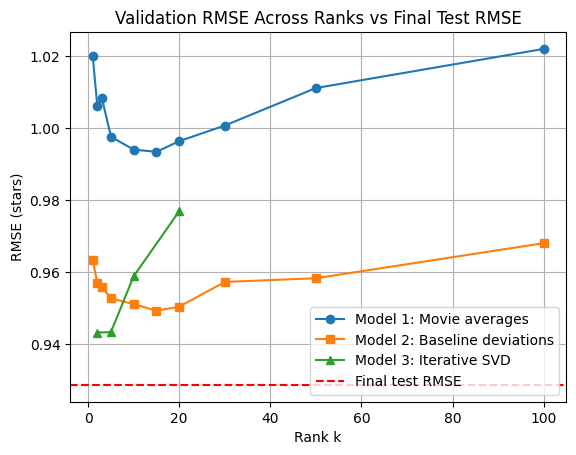

In [37]:
# 4 - Check for overfitting.

plt.plot(ks, val_err1, "o-", label="Model 1: Movie averages")
plt.plot(ks, val_err2, "s-", label="Model 2: Baseline deviations")
plt.plot(ks_iter, val_err3, "^-", label="Model 3: Iterative SVD")

plt.axhline(test_rmse, color="red", linestyle="--",
            label="Final test RMSE")

plt.xlabel("Rank k")
plt.ylabel("RMSE (stars)")
plt.title("Validation RMSE Across Ranks vs Final Test RMSE")

plt.grid()
plt.legend()

os.makedirs("figures", exist_ok=True)
plt.savefig("figures/overfitting_comparison.png", dpi=150)

plt.show()

As we can see from the above graph, results can vary at different ranks. It is for this reason that we should choose the rank. At rank 2, Model 3 performed the best, but decreased significantly in performances for rank higher than 2

### 5 - Cold-start limitation.

For a new user with no ratings, we can only use the overall average and movie averages to predict ratings; this is because the model acts based on previous rankings. It would be beneficial for users to enter a few ratings first before having the svd ran.  

In [38]:
print("Chosen model:", chosen_model)
print("Baseline test RMSE:", round(test_baseline, 4))
print("Chosen model test RMSE:", round(test_rmse, 4))

Chosen model: iterative SVD
Baseline test RMSE: 0.9545
Chosen model test RMSE: 0.9286


Chosen model: iterative SVD

Baseline test RMSE: 0.9545

Chosen model test RMSE: 0.9286

Above are shown the results. They show that Iterative SVD was able to make slightly more accurate predictions by learning patterns in how users rated different movies. Based on these results, we would expect the model to recommend movies that better match a user's preferences compared to the baseline. However, a lower RMSE does not guarantee that every recommendation will be a movie the user enjoys, since predicting ratings and making good recommendations are not exactly the same thing.